<a href="https://colab.research.google.com/github/JLettsSJU931/Machine-Learning-FA26/blob/main/HW7/wine_clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Imports:

In [77]:
from sklearn.datasets import load_wine
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from sklearn.metrics import pairwise_distances
from sklearn.cluster import DBSCAN
import hdbscan
from scipy.cluster.hierarchy import linkage
from scipy.cluster.hierarchy import dendrogram
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score

# **Task 1:** Print dataset dimensions, feature summary statistics, and missing value checks. Standardize all 13 features and display a comparison of feature distributions before and after scaling.

Here we start out with the standard loading and analysis of the wine dataset, as per usual. After that, I use a scaler to standardize the data, and make a sns boxplot to display the differences in the data.

Dataset Shape (Samples, Features): (178, 13)
Target Classes: ['class_0' 'class_1' 'class_2']

Class Distribution:
 target
0    59
1    71
2    48
Name: count, dtype: int64


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


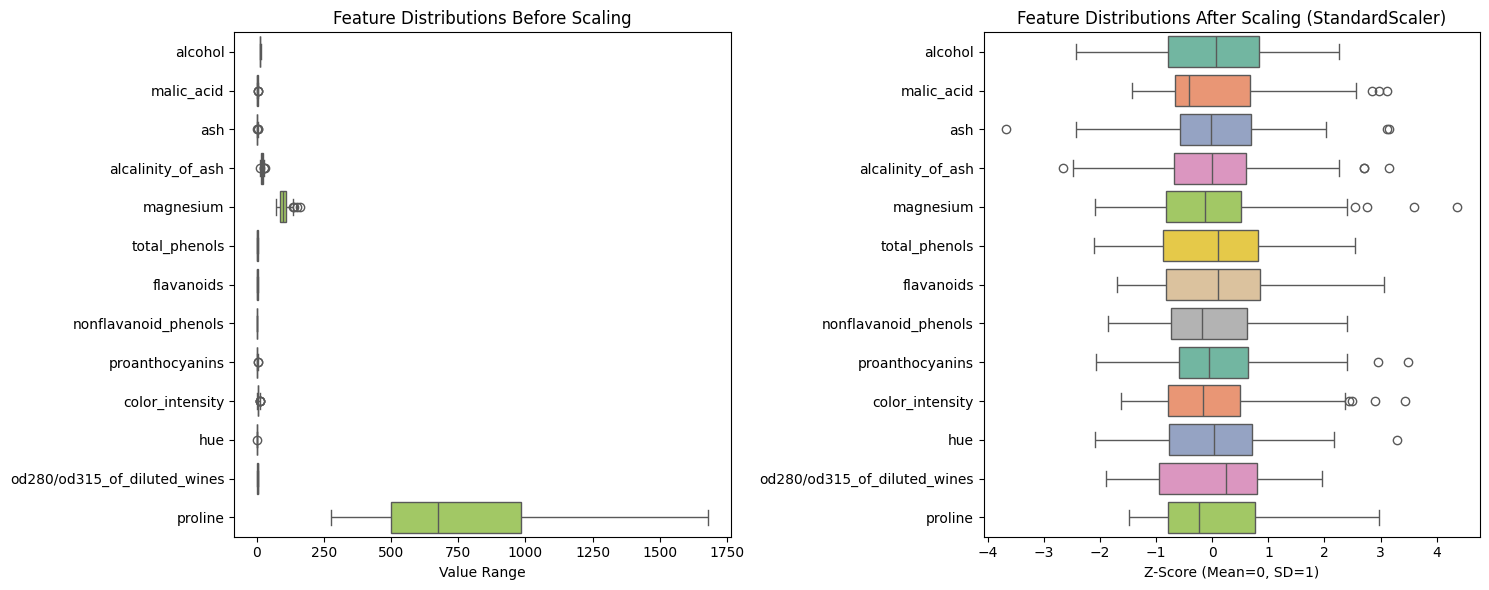

In [78]:
wine = load_wine(as_frame=True)
df = wine.frame
x = wine.data
y = wine.target
print("Dataset Shape (Samples, Features):", x.shape)
print("Target Classes:", wine.target_names)
print("\nClass Distribution:\n", pd.Series(y).value_counts().sort_index())
display(df.head())
X_train, X_test, y_train, y_test = train_test_split(x, y, random_state=69)
features = df.drop(columns=["target"])
scaler = StandardScaler()
sfa = scaler.fit_transform(features)
scaled_df = pd.DataFrame(sfa, columns=features.columns)
full_df = scaled_df
full_df["target"] = df["target"]
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=False)
sns.boxplot(data=features, orient="h", ax=axes[0], palette="Set2")
axes[0].set_title("Feature Distributions Before Scaling")
axes[0].set_xlabel("Value Range")
sns.boxplot(data=scaled_df.drop(columns=['target']), orient="h", ax=axes[1], palette="Set2")
axes[1].set_title("Feature Distributions After Scaling (StandardScaler)")
axes[1].set_xlabel("Z-Score (Mean=0, SD=1)")
plt.tight_layout()
plt.show()

# **Task 2:** Iterate k from 1 to 10 for K-Means clustering on the scaled features. Compute and plot side-by-side:

## 1. The Elbow Method curve .

## 2. The Silhouette Scores curve for k in [2, 10].

#Print the optimal k value suggested by both metrics.

Here we start by making arrays for inertia and silhouette, then making the k_range used for the latter before moving on to the kmeans. I make one for both types before going through the long process of manually finding the optimal k value for elbow (it is much easier for silhouette). Finally, I make the required plots and move one.

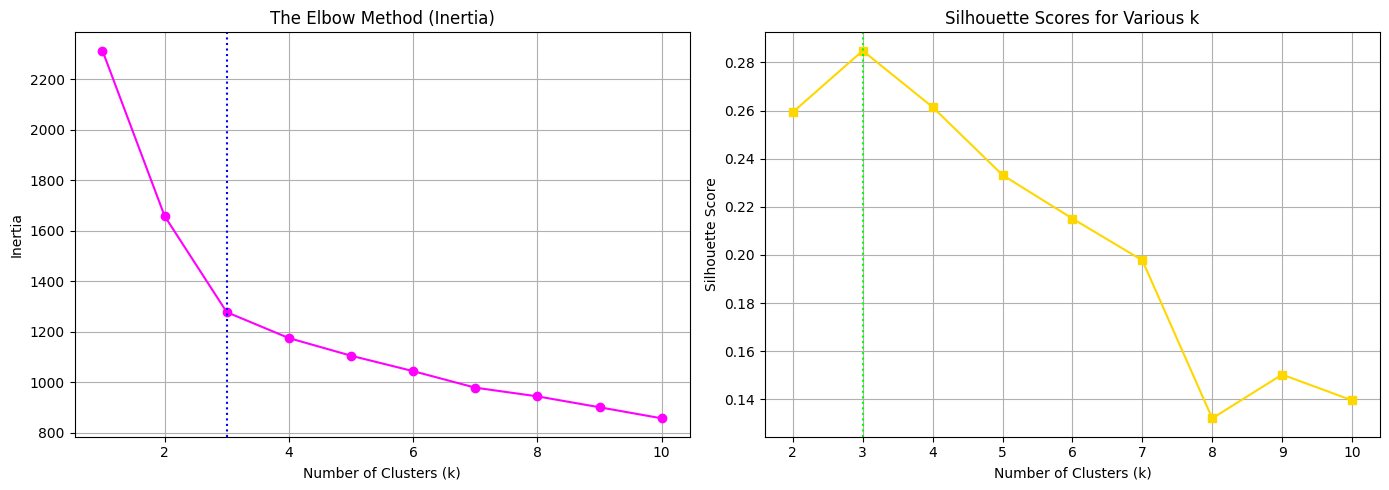

Optimal k for Elbow: 3
Optimal k for Silhouette: 3


In [79]:
inertia = []
s_scores = []
k_range = range(2, 11)
x_scaled = scaler.fit_transform(x)
for k in range(1,11) :
    kmeans_temp = KMeans(n_clusters=k, random_state=69, n_init=10)
    kmeans_temp.fit(x_scaled)
    inertia.append(kmeans_temp.inertia_)
for k in k_range:
    kmeans_temp = KMeans(n_clusters=k, random_state=69, n_init=10)
    labels = kmeans_temp.fit_predict(x_scaled)
    s_scores.append(silhouette_score(x_scaled, labels))
e_range = np.array(list(range(1, 11)))
k_val = np.array(inertia)
x_norm = (e_range - e_range.min()) / (e_range.max() - e_range.min())
y_norm = (k_val - k_val.min()) / (k_val.max() - k_val.min())
distances = np.abs(
    (y_norm[-1] - y_norm[0]) * x_norm
    - (x_norm[-1] - x_norm[0]) * y_norm
    + x_norm[-1] * y_norm[0]
    - y_norm[-1] * x_norm[0]
) / np.sqrt(
    (y_norm[-1] - y_norm[0])**2
    + (x_norm[-1] - x_norm[0])**2)
elbow_k = e_range[np.argmax(distances)]
silhouette_k = k_range[np.argmax(s_scores)]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.plot(range(1, 11), inertia, marker='o', color='magenta', linestyle='-')
ax1.axvline(elbow_k, color='blue', linestyle=':', label=f'Estimated Elbow k={elbow_k}')
ax1.set_title('The Elbow Method (Inertia)')
ax1.set_xlabel('Number of Clusters (k)')
ax1.set_ylabel('Inertia')
ax1.grid(True)
ax2.plot(k_range, s_scores, marker='s', color='gold', linestyle='-')
ax2.axvline(silhouette_k, color='lime', linestyle=':', label=f'Best Silhouette k={silhouette_k}')
ax2.set_title('Silhouette Scores for Various k')
ax2.set_xlabel('Number of Clusters (k)')
ax2.set_ylabel('Silhouette Score')
ax2.grid(True)
plt.tight_layout()
plt.show()
print("Optimal k for Elbow:", elbow_k)
print("Optimal k for Silhouette:", silhouette_k)


# **Task 3:** Apply PCA strictly to reduce the 13 scaled features down to 2 principal components for visualization purposes. Fit a K-Means model (k=3) on the 2D projected space. Plot the decision boundaries using the Voronoi method.

I start by making a PCA, as is standard since last assignment, fitting it to my scaled x value. I then mark down the optimal k value before making my PCA powered Kmeans and using it to make some centroids. I then generate some mins and maxes before plotting down a scatterplot.

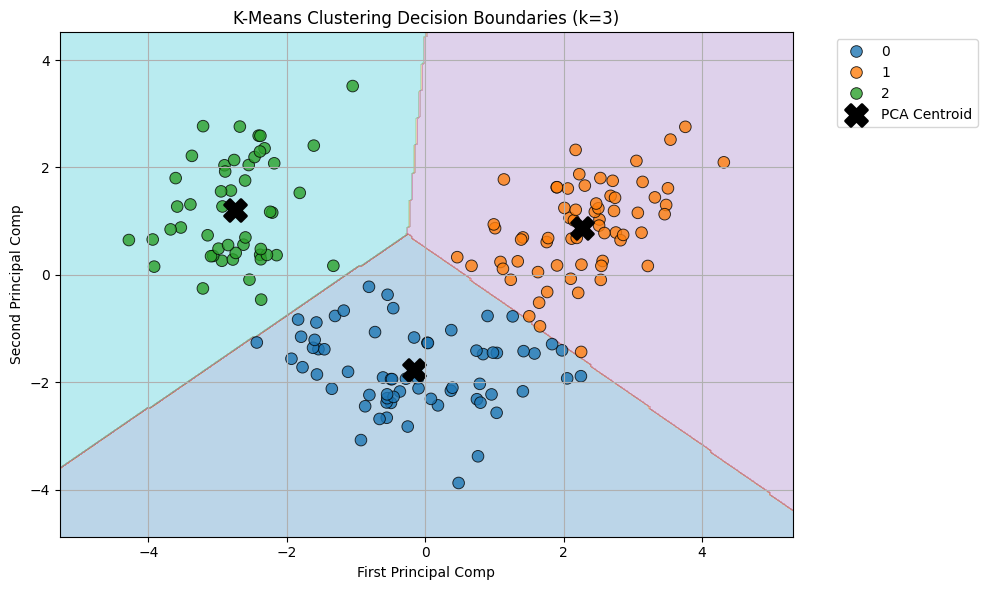

In [80]:
pca = PCA(n_components=2)
x_pca = pca.fit_transform(x_scaled)
true_k = 3
k_pca = KMeans(n_clusters=true_k, random_state=69, n_init=10)
pca_labels = k_pca.fit_predict(x_pca)
centroid_pca = k_pca.cluster_centers_
plt.figure(figsize=(10, 6))
x_min, x_max = x_pca[:, 0].min() - 1, x_pca[:, 0].max() + 1
y_min, y_max = x_pca[:, 1].min() - 1, x_pca[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
grid_points = np.c_[xx.ravel(), yy.ravel()]
z = k_pca.predict(grid_points)
z = z.reshape(xx.shape)
plt.contourf(xx, yy, z, alpha=0.3, cmap='tab10')
sns.scatterplot(
    x=x_pca[:, 0],
    y=x_pca[:, 1],
    hue= pca_labels,
    palette='tab10',
    s=70,
    alpha=0.8,
    edgecolor='k'
)
plt.scatter(
    centroid_pca[:, 0],
    centroid_pca[:, 1],
    marker='X',
    s=250,
    linewidths=2,
    color='black',
    label='PCA Centroid'
)
plt.title('K-Means Clustering Decision Boundaries (k=3)')
plt.xlabel('First Principal Comp')
plt.ylabel('Second Principal Comp')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True)
plt.tight_layout()
plt.show()


# **Task 4:** Select 5 representative wine samples from the dataset. Using the fitted 13-feature K-Means model (k=3), compute the distance matrix. Generate and display a heatmap visualizing the soft clustering distance profiles across all 3 cluster centroids, highlighting the minimum distance corresponding to each sample's hard cluster assignment.

Choosing 5 random numbers that seem in range, I make a proper Kmean and scale the numbers before transforming them into a distance matrix, also taking the time to predict some clusters. I show the data on a heatmap and move on.

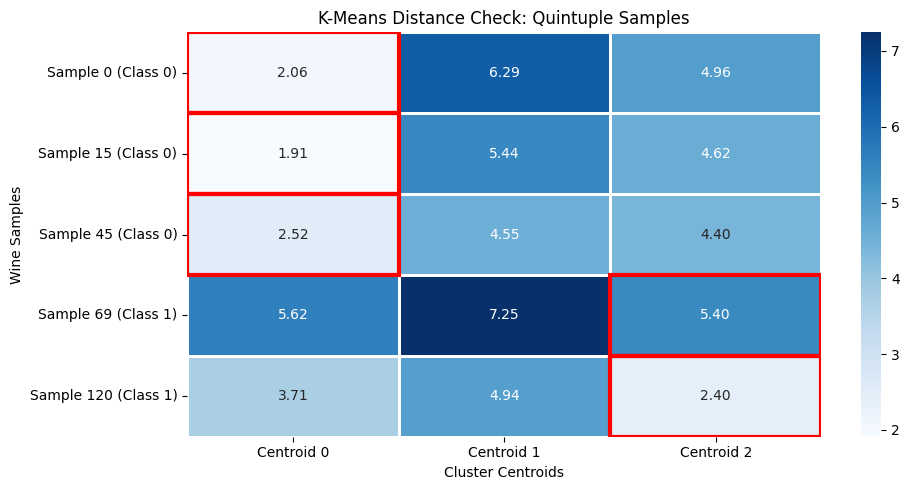

In [81]:
full_k = KMeans(n_clusters=true_k, random_state=69, n_init=10)
k_labels = full_k.fit_predict(x_scaled)
x_new = [0, 15, 45, 69, 120]
x_new_scaled = x_scaled[x_new]
dist_matrix = full_k.transform(x_new_scaled)
hard_cluster = full_k.predict(x_new_scaled)
plt.figure(figsize=(10, 5))
sample_labels = [
    f"Sample {idx} (Class {wine.target[idx]})" for idx in x_new
]
cluster_labels = ["Centroid 0", "Centroid 1", "Centroid 2"]
df_dist = pd.DataFrame(
    dist_matrix, index=sample_labels, columns=cluster_labels
)
ax = sns.heatmap(df_dist, annot=True, fmt='.2f', cmap='Blues', linewidths=1)
for row in range(len(dist_matrix)):
    col = hard_cluster[row]
    ax.add_patch(plt.Rectangle((col, row), 1, 1, fill=False, edgecolor='red', linewidth=3))
plt.title('K-Means Distance Check: Quintuple Samples')
plt.xlabel('Cluster Centroids')
plt.ylabel('Wine Samples')
plt.tight_layout()
plt.show()


# **Task 5:** Fit a DBSCAN model on the 13-dimensional scaled feature space. Experiment with the two needed hyperparameter settings. Print the number of identified clusters and noise points. Visualize the DBSCAN assignments on the 2D PCA projection space, clearly distinguishing noise points from core cluster members.

I experiment with various values for eps and minimum samples before making a loop to fit the dbscans on my features. I find labels and begin plotting the projection, showing an excessive amount of noise.


DBSCAN Experiment #1
Params: {'eps': 0.5, 'min_samples': 5}
Estimated number of clusters: 0
Estimated number of noise points: 178

DBSCAN Experiment #2
Params: {'eps': 1.0, 'min_samples': 5}
Estimated number of clusters: 0
Estimated number of noise points: 178

DBSCAN Experiment #3
Params: {'eps': 2.0, 'min_samples': 5}
Estimated number of clusters: 5
Estimated number of noise points: 85

DBSCAN Experiment #4
Params: {'eps': 0.5, 'min_samples': 6}
Estimated number of clusters: 0
Estimated number of noise points: 178

DBSCAN Experiment #5
Params: {'eps': 1.0, 'min_samples': 6}
Estimated number of clusters: 0
Estimated number of noise points: 178

DBSCAN Experiment #6
Params: {'eps': 2.0, 'min_samples': 6}
Estimated number of clusters: 3
Estimated number of noise points: 100


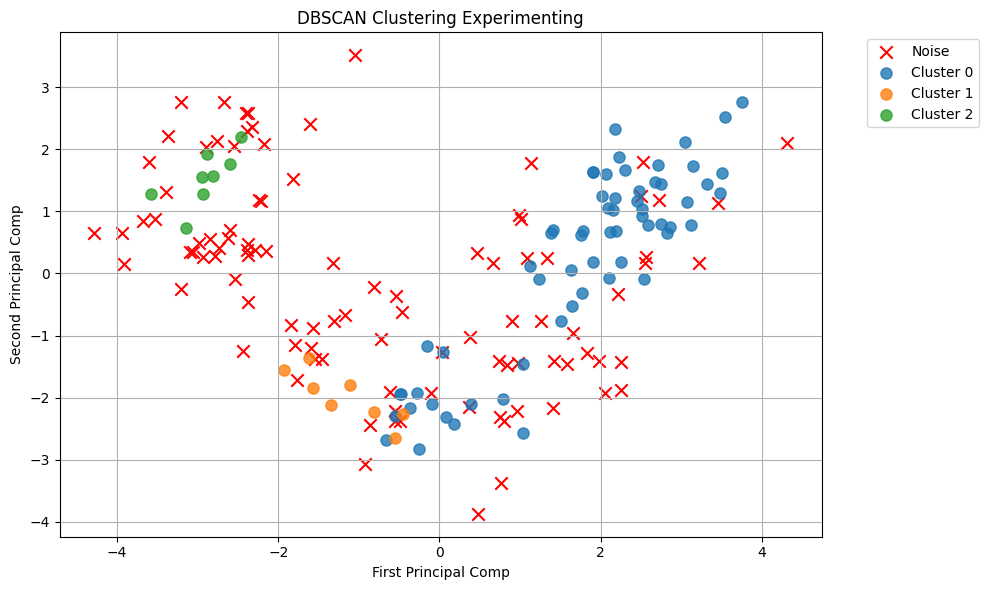

In [82]:
dbscan_exp = [
    {'eps': 0.5, 'min_samples': 5},
    {'eps': 1.0, 'min_samples': 5},
    {'eps': 2.0, 'min_samples': 5},
    {'eps': 0.5, 'min_samples': 6},
    {'eps': 1.0, 'min_samples': 6},
    {'eps': 2.0, 'min_samples': 6}]
dbscan_results = {}
for i, params in enumerate(dbscan_exp, start=1):
    dbscan = DBSCAN(eps=params['eps'], min_samples=params['min_samples'])
    labels = dbscan.fit_predict(x_scaled)
    dbscan_results[i] = labels
    n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise_ = list(labels).count(-1)
    print(f"\nDBSCAN Experiment #{i}")
    print("Params:", params)
    print(f"Estimated number of clusters: {n_clusters_}")
    print(f"Estimated number of noise points: {n_noise_}")
dbscan_labels = dbscan.fit_predict(x_scaled)
plt.figure(figsize=(10, 6))
unique_labels = sorted(set(dbscan_labels))
for label in unique_labels:
    mask = dbscan_labels == label
    if label == -1:
        plt.scatter(x_pca[mask, 0], x_pca[mask, 1], c='red', marker='x', s=80, label='Noise')
    else:
        plt.scatter(x_pca[mask, 0], x_pca[mask, 1], s=65, alpha=0.8, label=f'Cluster {label}')
plt.title('DBSCAN Clustering Experimenting')
plt.xlabel('First Principal Comp')
plt.ylabel('Second Principal Comp')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True)
plt.tight_layout()
plt.show()

# **Task 6:** Fit an HDBSCAN model (using min_cluster_size=5 or min_samples=5) on the 13-dimensional scaled feature space. Print the total number of clusters discovered and noise points detected. Visualize the resulting HDBSCAN cluster assignments on the 2D PCA projection space.

This one is basically the same as the last, except I put an h in front of the dbscan and dont have to experiment with parameters, so it is even easier.

Estimated number of HDBSCAN clusters: 2
Estimated number of HDBSCAN noise points: 70


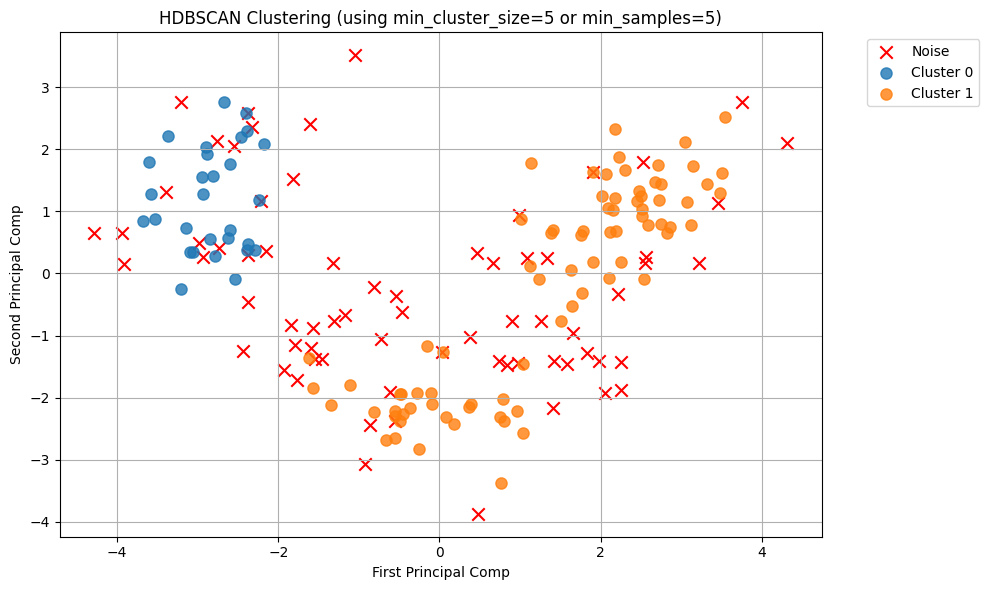

In [83]:
hdbscan_model = hdbscan.HDBSCAN(min_cluster_size=5, min_samples=5)
hdbscan_labels = hdbscan_model.fit_predict(x_scaled)
n_hdbscan_clusters_ = len(set(hdbscan_labels)) - (1 if -1 in hdbscan_labels else 0)
n_hdbscan_noise_ = list(hdbscan_labels).count(-1)
print(f"Estimated number of HDBSCAN clusters: {n_hdbscan_clusters_}")
print(f"Estimated number of HDBSCAN noise points: {n_hdbscan_noise_}")
plt.figure(figsize=(10, 6))
unique_labels = sorted(set(hdbscan_labels))
for label in unique_labels:
    mask = hdbscan_labels == label
    if label == -1:
        plt.scatter(x_pca[mask, 0], x_pca[mask, 1], c='red', marker='x', s=80, label='Noise')
    else:
        plt.scatter(x_pca[mask, 0], x_pca[mask, 1], s=65, alpha=0.8, label=f'Cluster {label}')
plt.title('HDBSCAN Clustering (using min_cluster_size=5 or min_samples=5)')
plt.xlabel('First Principal Comp')
plt.ylabel('Second Principal Comp')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True)
plt.tight_layout()
plt.show()

# **Task 7:** Compute a single-linkage hierarchical clustering matrix on the scaled Wine features. Plot a hierarchical clustering dendrogram to visualize how individual chemical profiles merge across distance thresholds, connecting the visual structure to HDBSCAN's stability extraction mechanics.
I put my scaled x into some linkage and immediately put the values into a dendrogram, creating an admittedly incomprehensible graph.

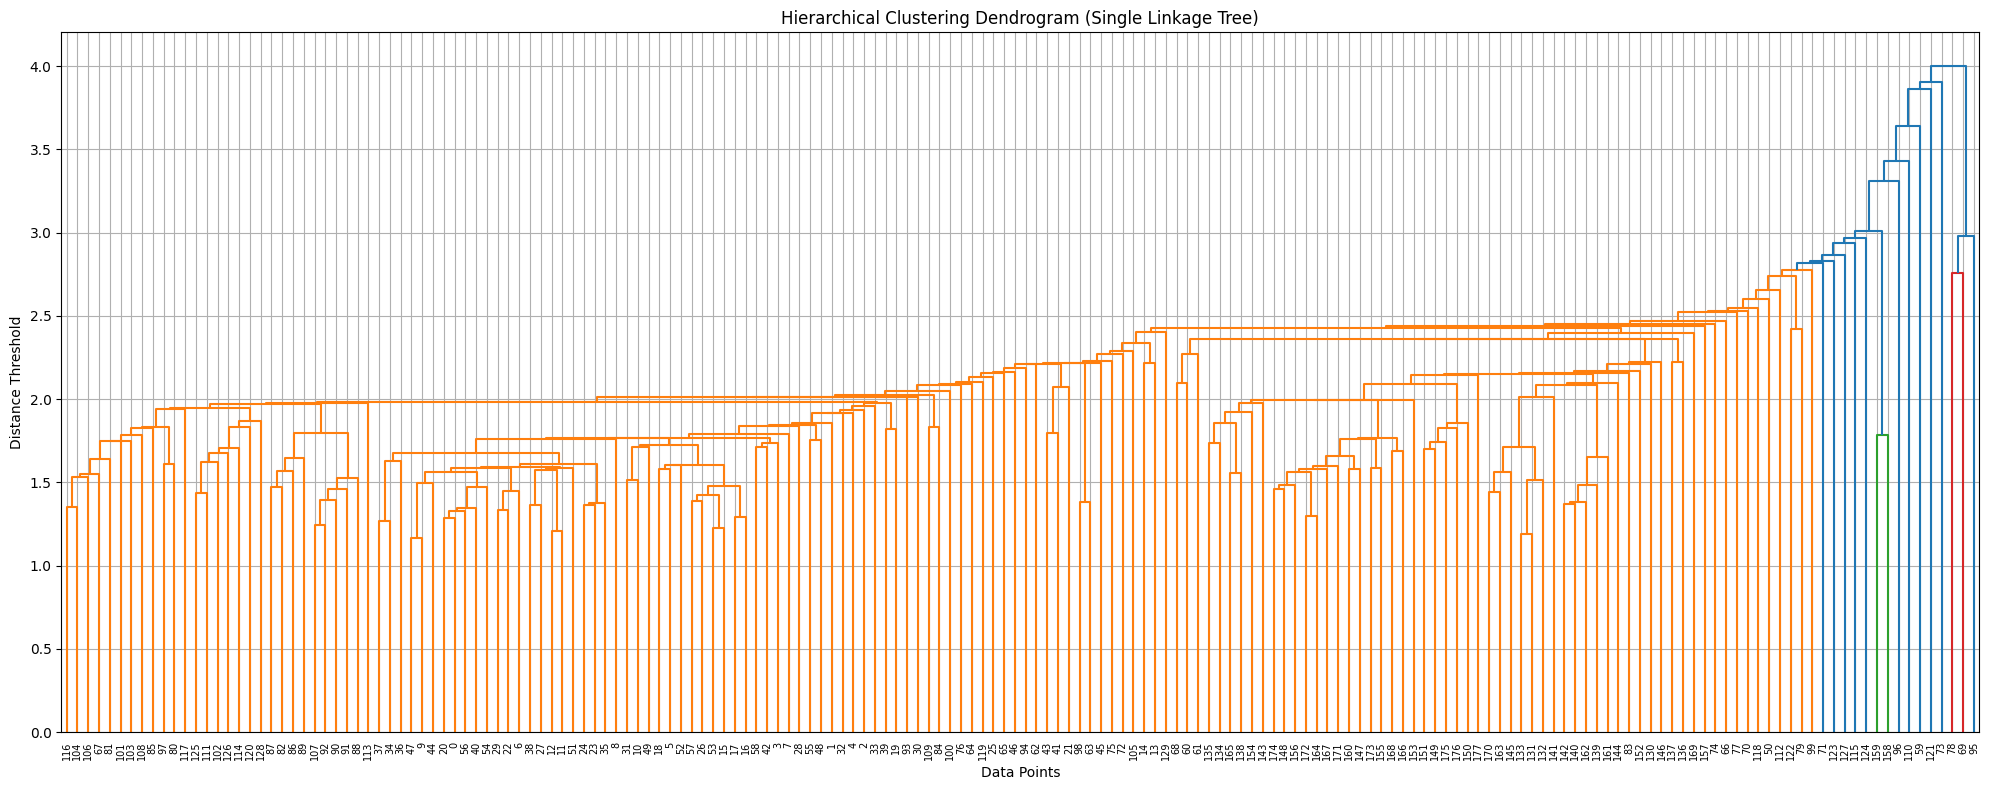

In [84]:
linked = linkage(x_scaled, method='single')
plt.figure(figsize=(20, 8))
dendrogram(
    linked,
    orientation='top',
    distance_sort='descending',
    p=30,
    leaf_rotation=90,
    leaf_font_size=7,
    show_contracted=True
)
plt.title('Hierarchical Clustering Dendrogram (Single Linkage Tree)')
plt.xlabel('Data Points')
plt.ylabel('Distance Threshold')
plt.grid(True)
plt.tight_layout()
plt.show()

# **Task 8:** Treat the cluster assignments generated by K-Means (k=3), DBSCAN, and HDBSCAN as categorical feature representations or pseudo-labels. Perform a stratified train/test split (80/20) on the Wine dataset and conduct an experiment: train a supervised classifier such as a Random Forest or Logistic Regression using these cluster labels to predict the actual ground-truth wine cultivars (Class 0, 1, 2). Plot the classification accuracy and Silhouette Scores for all three algorithms.

In an all star hits compilation of several of our previous projects, I make new training and testing variables and make a list of models and results. A loop then begins I make a pipeline, fit the data to it, find the accuracy and silhouette scores, and stash them in the array of results. Finally, the results are plotted and I am done here.

K-Means:
Accuracy: 0.69
Silhouette Score: 0.28

DBSCAN:
Accuracy: 0.69
Silhouette Score: 0.28

HDBSCAN:
Accuracy: 0.69
Silhouette Score: 0.36



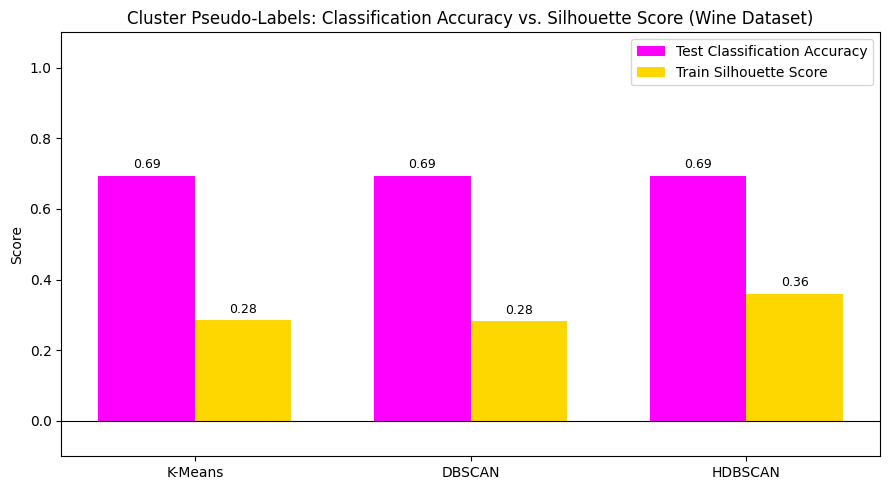

In [92]:
cluster_models = {'K-Means': k_labels, 'DBSCAN': dbscan_labels, 'HDBSCAN': hdbscan_labels}
results = {}
X_train, X_test, y_train, y_test = train_test_split(x_scaled, y, test_size=0.20, random_state=69, stratify=y)
for name, model in cluster_models.items():
  print(f'{name}:')
  log = Pipeline([
        ('encoder', OneHotEncoder(handle_unknown='ignore')),
        ('model', LogisticRegression(max_iter=1000, random_state=69))])
  log.fit(X_train, y_train)
  y_pred = log.predict(X_test)
  acc = accuracy_score(y_test, y_pred)
  true_mask = model != -1
  true_model = model[true_mask]
  true_features = x_scaled[true_mask]
  n_clusters_ = len(np.unique(true_model))
  if 2 <= n_clusters_ < len(true_model):
      sil_score = silhouette_score(true_features, true_model)
  else:
      sil_score = np.nan
  results[name] = {
        "Accuracy": acc,
        "Silhouette": sil_score,
        "Unique Clusters": list(unique_labels)
    }
  print(f"Accuracy: {acc:.2f}")
  print(f"Silhouette Score: {sil_score:.2f}")
  print()
labels = list(results.keys())
accs = [results[m]["Accuracy"] for m in labels]
sils = [results[m]["Silhouette"] for m in labels]
x = np.arange(len(labels))
width = 0.35
fig, ax = plt.subplots(figsize=(9, 5))
rects1 = ax.bar(x - width/2, accs, width, label="Test Classification Accuracy", color="magenta")
rects2 = ax.bar(x + width/2, sils, width, label="Train Silhouette Score", color="gold")
ax.set_ylabel("Score")
ax.set_title("Cluster Pseudo-Labels: Classification Accuracy vs. Silhouette Score (Wine Dataset)")
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylim(-0.1, 1.1)
ax.axhline(0, color="black", linewidth=0.8)
ax.legend()
for rect in rects1 + rects2:
    height = rect.get_height()
    if not np.isnan(height):
        ax.annotate(f"{height:.2f}",
                    xy=(rect.get_x() + rect.get_width() / 2, max(height, 0)),
                    xytext=(0, 3), textcoords="offset points",
                    ha="center", va="bottom", fontsize=9)

plt.tight_layout()
plt.show()